In [21]:

import pandas as pd
df=pd.read_csv(r"C:\Users\Lenovo\Downloads\archive (4)\spam.csv",encoding='latin-1')

In [22]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [23]:
df=df.drop(['Unnamed: 2','Unnamed: 3','Unnamed: 4'],axis=1)
df=df.rename(columns={'v1':'lable','v2':'text'})
df.head()

,lable,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [24]:
df['lable'].value_counts()

lable
ham     4825
spam     747
Name: count, dtype: int64

In [25]:
import re
def clean_text(text):
    text=text.lower()
    text=re.sub(r'[^\w\s]','',text)
    return text
df['text']=df['text'].apply(clean_text)

In [26]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
stop_words=set(stopwords.words('english'))
def remove_stopwords(text):
    words=text.split()
    filtered=[word for word in words if word not in stop_words]
    return" ".join(filtered)
df['text']=df['text'].apply(remove_stopwords)
    
    

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [27]:
df['text'].head()

0    go jurong point crazy available bugis n great ...
1                              ok lar joking wif u oni
2    free entry 2 wkly comp win fa cup final tkts 2...
3                  u dun say early hor u c already say
4          nah dont think goes usf lives around though
Name: text, dtype: object

In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf=TfidfVectorizer()
x=tfidf.fit_transform(df['text'])
y=df['lable']

In [29]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [30]:
from sklearn.linear_model import LogisticRegression

In [31]:
model=LogisticRegression(max_iter=1000)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

In [32]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Accuracy",accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

Accuracy 0.9417040358744395
[[961   4]
 [ 61  89]]
              precision    recall  f1-score   support

         ham       0.94      1.00      0.97       965
        spam       0.96      0.59      0.73       150

    accuracy                           0.94      1115
   macro avg       0.95      0.79      0.85      1115
weighted avg       0.94      0.94      0.94      1115



In [33]:
model=LogisticRegression(class_weight='balanced',max_iter=1000)

In [34]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Accuracy",accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

Accuracy 0.9417040358744395
[[961   4]
 [ 61  89]]
              precision    recall  f1-score   support

         ham       0.94      1.00      0.97       965
        spam       0.96      0.59      0.73       150

    accuracy                           0.94      1115
   macro avg       0.95      0.79      0.85      1115
weighted avg       0.94      0.94      0.94      1115



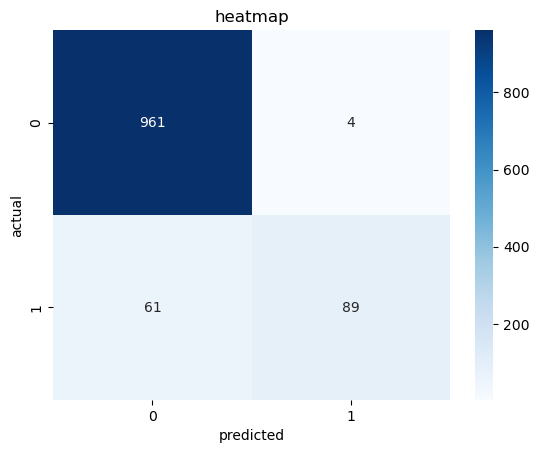

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.xlabel("predicted")
plt.ylabel('actual')
plt.title("heatmap")
plt.show()

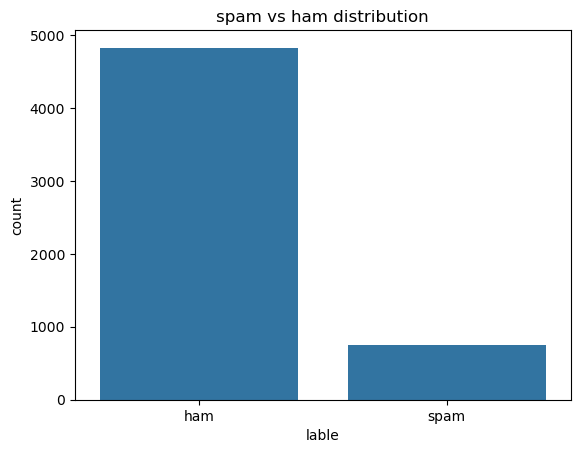

In [36]:
sns.countplot(x=df['lable'])
plt.title("spam vs ham distribution")
plt.show()

In [40]:
# ====== IMPORTS ======
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# ====== VECTORIZATION ======
tfidf = TfidfVectorizer()
X = tfidf.fit_transform(df['text'])
y = df['lable']

# ====== SPLIT ======
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# ====== MODEL ======
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

print("Model trained successfully ✅")

# ====== USER INPUT ======
user_input = input("Enter a message: ")

# preprocessing
cleaned = clean_text(user_input)
cleaned = remove_stopwords(cleaned)

# vectorize
vector = tfidf.transform([cleaned])

# prediction
prediction = model.predict(vector)[0]
probability = model.predict_proba(vector)[0]

# output
if prediction == 'spam':
    print("⚠️ This is SPAM")
else:
    print("✅ This is HAM")

print(f"Spam Probability: {probability[1]:.2f}")

Model trained successfully ✅


Enter a message:  free moneu win now


⚠️ This is SPAM
Spam Probability: 0.85
